In [87]:
import networkx as nx
import numpy as np

import matplotlib.pyplot as plt

In [94]:
#this python notebook is to submit homework for dynamic process chapter

def max_node(
    candidate_nodes: dict
  ):

  keys= np.asarray(list(candidate_nodes.keys()))
  values = np.asarray(list(candidate_nodes.values()))
  max_idx = np.where(values == max(values), )[0]

  max_choice = np.random.choice(max_idx)
  maxn = keys[max_choice]

  return maxn

def candidate_nodes(
    G:nx.Graph,
  ):

  inactive_nodes = [node for node in list(G.nodes) if G.nodes[node]["active"] == False]
  candidate_nodes = dict([])
  for node in inactive_nodes:
    adj_nodes = G.adj[node]

    adj_active_nodes = [i for i in adj_nodes if G.nodes[i]["active"] == True]
    for n in adj_active_nodes:
      candidate_nodes[n] = G.degree(n)

  return candidate_nodes

def attack_strategy(G: nx.Graph, initial_attack_list: list, timestep= None):
  # Safely handle an empty graph to prevent ValueError
  len_lcc = lambda x: len(max(nx.connected_components(x), key=len)) if len(x) > 0 else 0
  ind_sub_g = lambda x: nx.induced_subgraph(x, [node for node in G.nodes if G.nodes[node]["active"] == True])

  lcc = {}
  for node in initial_attack_list:
    G.nodes[node]["active"] = False

  sub_G = ind_sub_g(G)
  lcc[0] = len_lcc(sub_G)

  if timestep is None:
    timestep = len(sub_G)

  for i in range(1, timestep+1):
    c_nodes = candidate_nodes(G)

    if len(c_nodes) == 0:
      # Pad the remaining timesteps with the last known LCC size instead of just breaking
      for j in range(i, timestep + 1):
          lcc[j] = lcc[i - 1]
      break

    maxn = max_node(c_nodes)
    G.nodes[maxn]["active"] = False
    sub_G = ind_sub_g(G)
    lcc[i] = len_lcc(sub_G)

  return lcc, G

In [90]:
ba_G = nx.barabasi_albert_graph(n=1000, m=3)
active = {n: True for n in list(ba_G.nodes)}
nx.set_node_attributes(ba_G, active, "active")



In [97]:
def homework1_plot1():
  def single_run():
    # Initialize graph with each node being active
    ba_G = nx.barabasi_albert_graph(n=1000, m=3)
    active = {n: True for n in list(ba_G.nodes)}
    nx.set_node_attributes(ba_G, active, "active")

    # Initialize initial attacked nodes
    random_init = list(np.random.choice(list(ba_G.nodes), size=5))
    weighted_init = sorted(list(ba_G.nodes), key=lambda x: ba_G.degree[x], reverse=True)[:5]

    # Attack graph twice
    random_lcc, _ = attack_strategy(
      G=ba_G, 
      initial_attack_list=random_init, 
      timestep=20
      )
    weighted_lcc, _ = attack_strategy(
      G=ba_G, 
      initial_attack_list=weighted_init, 
      timestep=20
      )

    return random_lcc, weighted_lcc


  r, w = single_run()
  random_lccs = np.asarray(list(r.values()))
  weighted_lccs = np.asarray(list(w.values()))

  plt.plot(range(0, 21), random_lccs, label="Random")
  plt.plot(range(0, 21), weighted_lccs, label="Largest")
  plt.xlabel("Attack step")
  plt.ylabel("Size of largest connected component")
  plt.legend()
  plt.show()


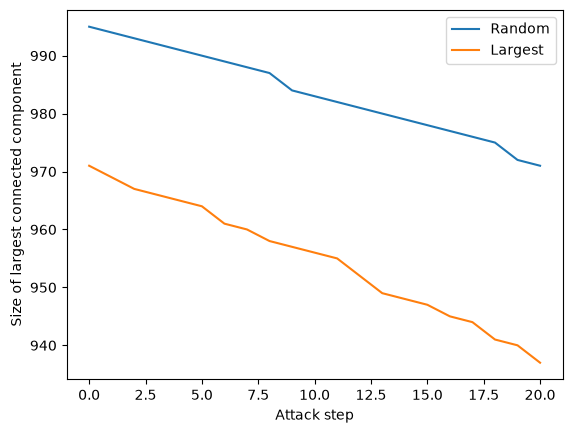

In [98]:
homework1_plot1()

In [ ]:
def homework1_plot2():
  def single_run():
      # Initialize graph with each node being active
      ba_G = nx.gnm_random_graph(n=1000, m=3000)
      active = {n: True for n in list(ba_G.nodes)}
      nx.set_node_attributes(ba_G, active, "active")
  
      # Initialize initial attacked nodes
      random_init = list(np.random.choice(list(ba_G.nodes), size=3))
      weighted_init = sorted(list(ba_G.nodes), key=lambda x: ba_G.degree[x], reverse=True)[:3]
  
      # Attack graph twice
      random_lcc, _ = attack_strategy(
        G=ba_G, 
        initial_attack_list=random_init, 
        timestep=20
        )
      weighted_lcc, _ = attack_strategy(
        G=ba_G, 
        initial_attack_list=weighted_init, 
        timestep=20
        )
  
      return random_lcc, weighted_lcc
  
  
  r, w = single_run()
  random_lccs = np.asarray(list(r.values()))
  weighted_lccs = np.asarray(list(w.values()))

  plt.plot(range(0, 21), random_lccs, label="Random")
  plt.plot(range(0, 21), weighted_lccs, label="Largest")
  plt.xlabel("Attack step")
  plt.ylabel("Size of largest connected component")
  plt.legend()
  plt.show()

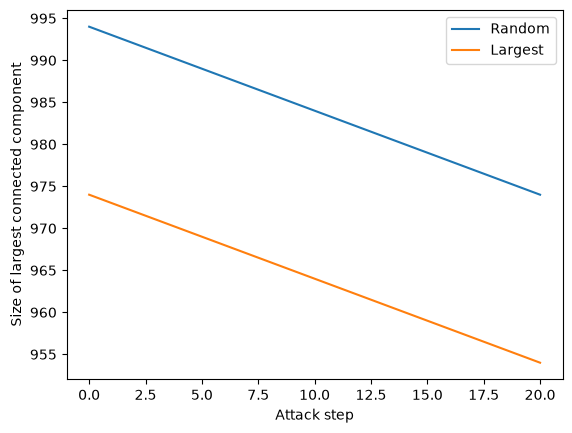

In [78]:
homework1_plot2()

Add your explanation for the above these two plots:

In [ ]:
def immunization_strategy(G, initial_propagator, k):
  #add the code to simulate the immunization strategy asked in Homework 2.

In [ ]:
def simulate_independent_cascade(G, initial_infected_nodes, infection_prob):
  #This function needs to be called from homework2_plot1. You can use the course from the python notebook that we shared for this chapter.

In [ ]:
def homework2_plot1():
  #write the code to make plot 1 of the homework 2
  #this method needs to call ICM model and for this you can use the code provided in the course python notebook

In [ ]:
def competitive_linear_threshold_model(G, initial_infected_nodes_1, initial_infected_nodes_2, threshold_1, threshold_2):
  #implement the code to simulate competitive linear threshold model

In [ ]:
def homework3_plot1():
  #write the code to make plot 1 of the homework 3